# the first question 


In [12]:
# imports 
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 




In [2]:
# load data 
diabetes = pd.read_csv('../datasets/diabetes.csv')
diabetes.head(5)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# checking lost variables 
diabetes.isnull().sum(axis = 0)

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [4]:
# optimize the costs 
diabetes['BMI'].head(10)
# as you can see even the bmi is integer type 

0    40.0
1    25.0
2    28.0
3    27.0
4    24.0
5    25.0
6    30.0
7    25.0
8    30.0
9    24.0
Name: BMI, dtype: float64

In [5]:
diabetes = diabetes.convert_dtypes()
# this will convert all the dtypes to their optimized version 

In [6]:
# finding all the unique values in each column

diabetes.apply(lambda x : x.unique() ,axis= 0)

Diabetes_012                                                    [0, 2, 1]
HighBP                                                             [1, 0]
HighChol                                                           [1, 0]
CholCheck                                                          [1, 0]
BMI                     [40, 25, 28, 27, 24, 30, 34, 26, 33, 21, 23, 2...
Smoker                                                             [1, 0]
Stroke                                                             [0, 1]
HeartDiseaseorAttack                                               [0, 1]
PhysActivity                                                       [0, 1]
Fruits                                                             [0, 1]
Veggies                                                            [1, 0]
HvyAlcoholConsump                                                  [0, 1]
AnyHealthcare                                                      [1, 0]
NoDocbcCost                           

In [7]:
# identify duplicate rows 

diabetes.duplicated().sum()

np.int64(23899)

In [8]:
#drop all the duplicates expect the first occurance 
diabetes.drop_duplicates(inplace= True )

               Count  percent
no diabetes   190055    82.71
pre diabetes    4629     2.01
diabetes       35097    15.27


<Axes: xlabel='Diabetes_012'>

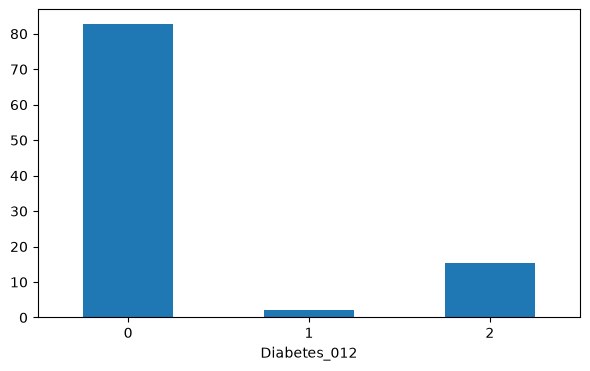

In [9]:
target = 'Diabetes_012'
class_count = diabetes['Diabetes_012'].value_counts().sort_index()
class_perc = (diabetes['Diabetes_012'].value_counts(normalize= True).sort_index() * 100)
class_summery = pd.DataFrame({'Count':class_count , 'percent': class_perc})
class_summery.index = ['no diabetes' , 'pre diabetes' , 'diabetes']
print(class_summery.round(2))
class_perc.plot(kind = 'bar' , figsize = (7,4) , rot = 0)


/tmp/ipykernel_1206/132250431.py:6: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data= data , x = x, hue = 'Diabetes_012' , multiple= 'stack' , ax = ax2 )
/tmp/ipykernel_1206/132250431.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))


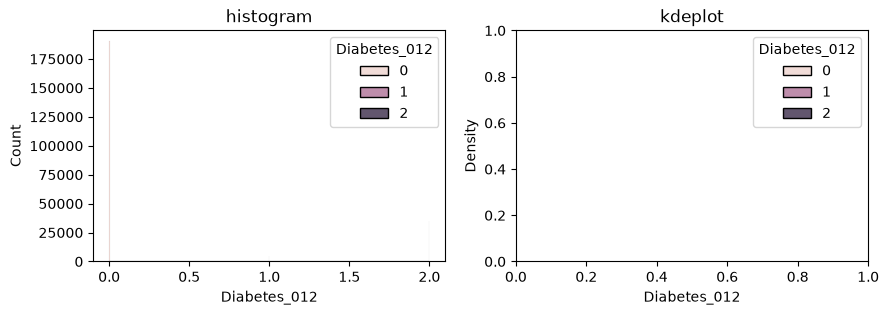

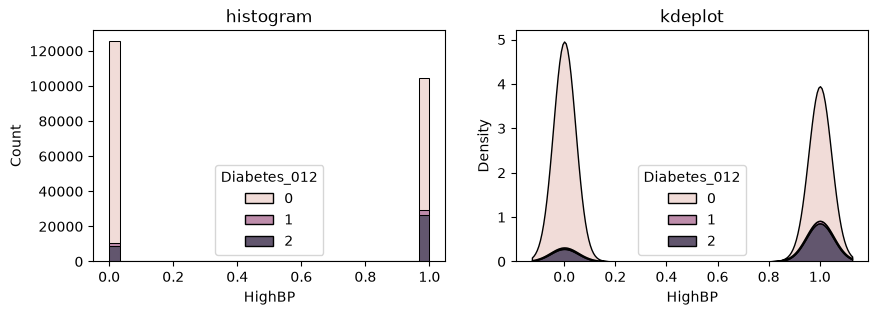

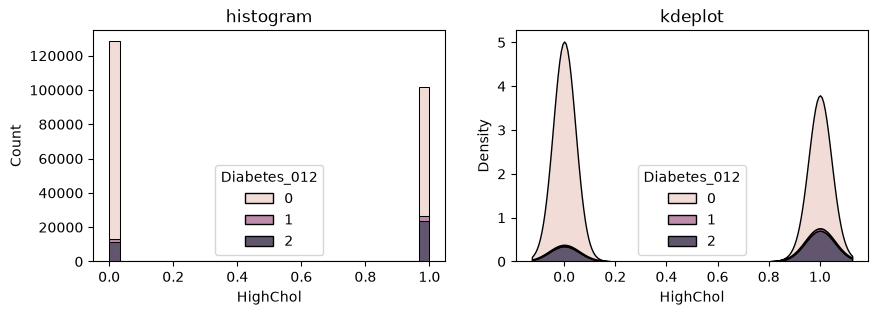

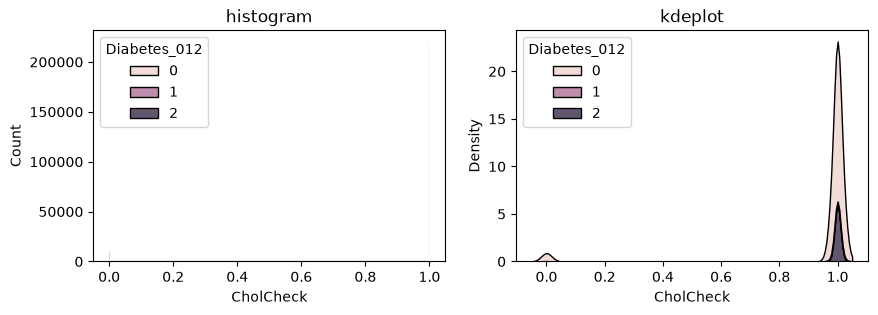

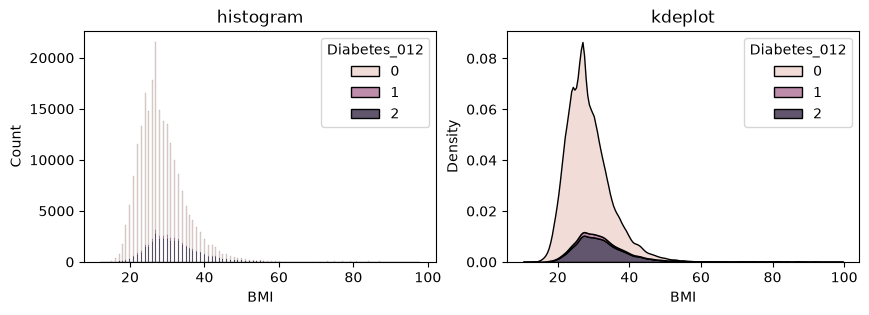

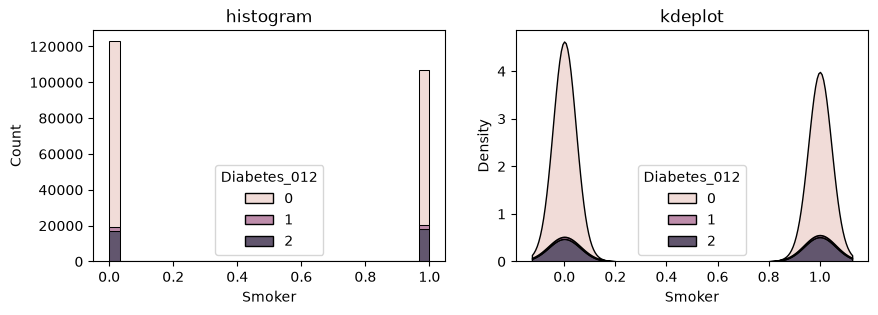

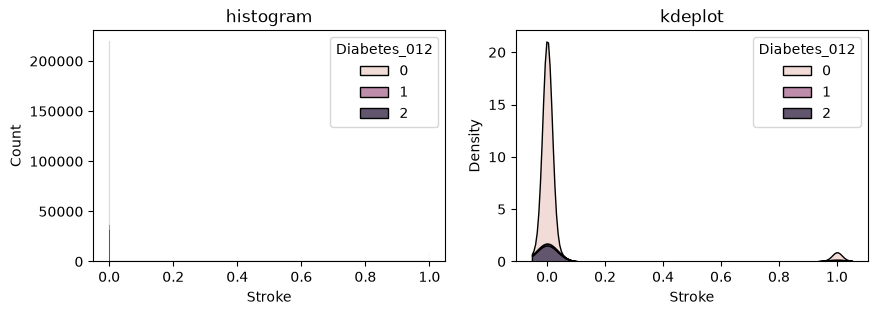

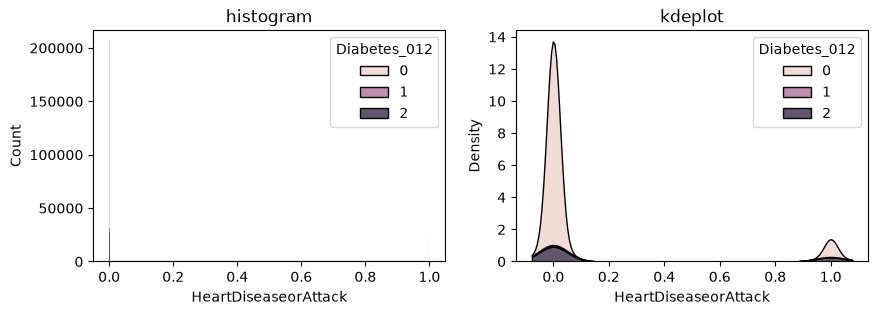

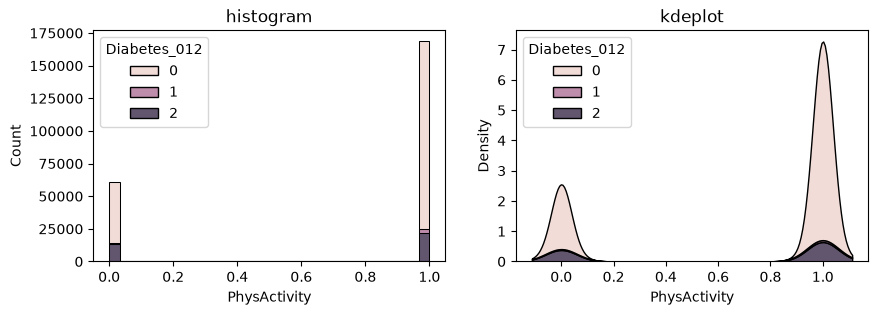

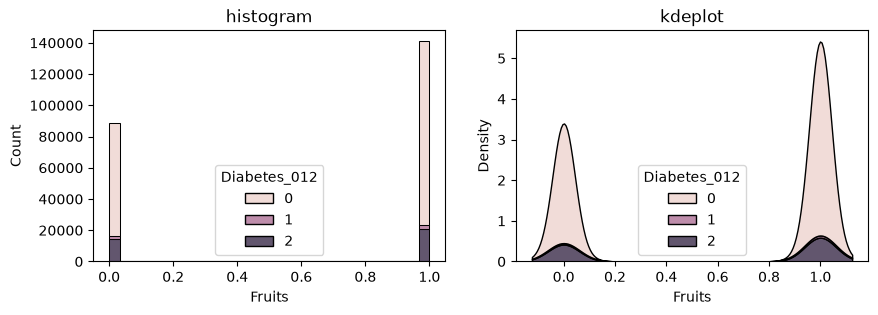

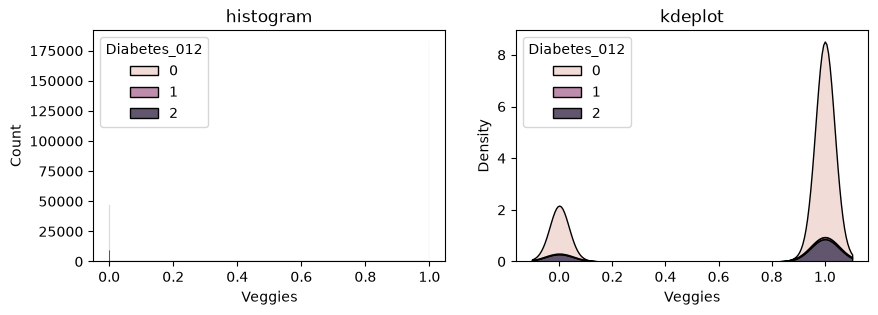

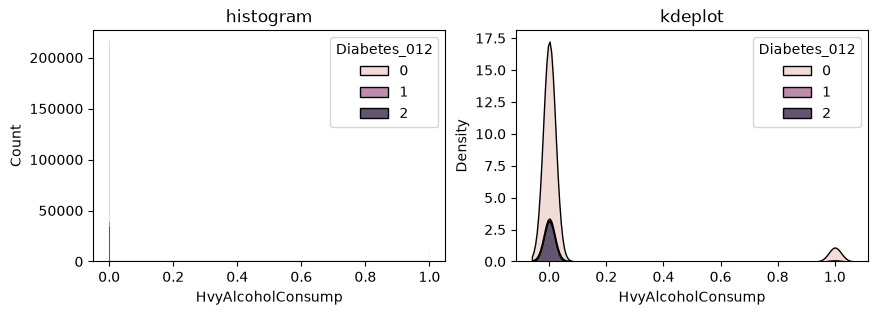

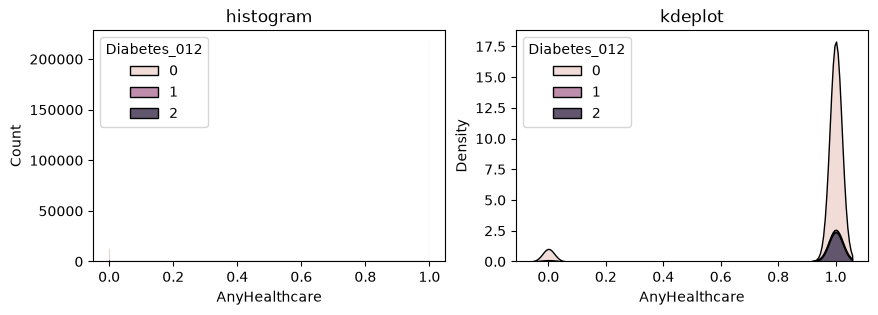

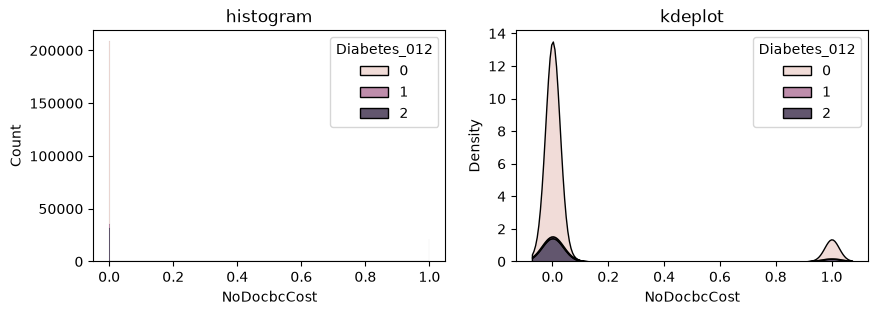

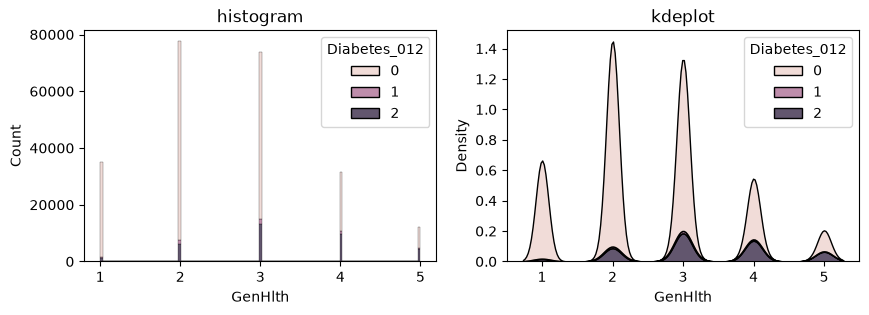

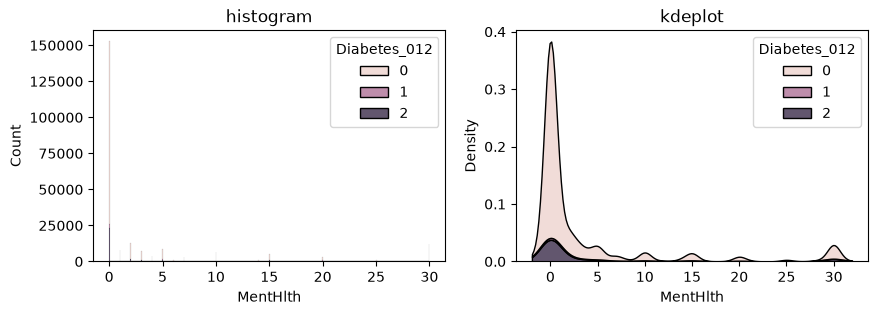

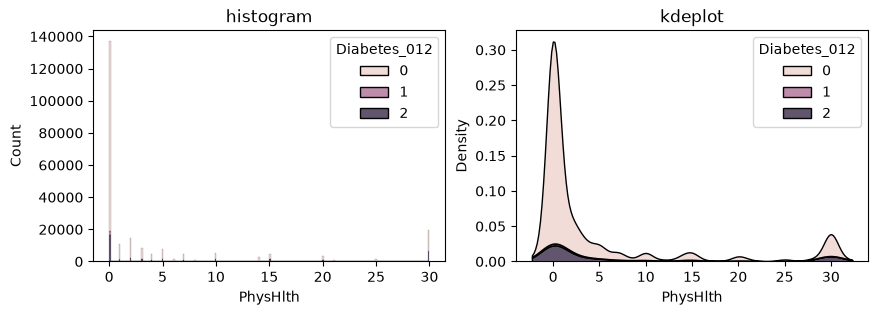

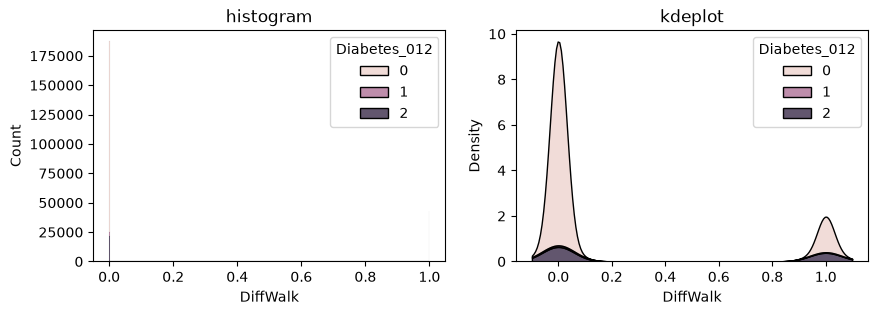

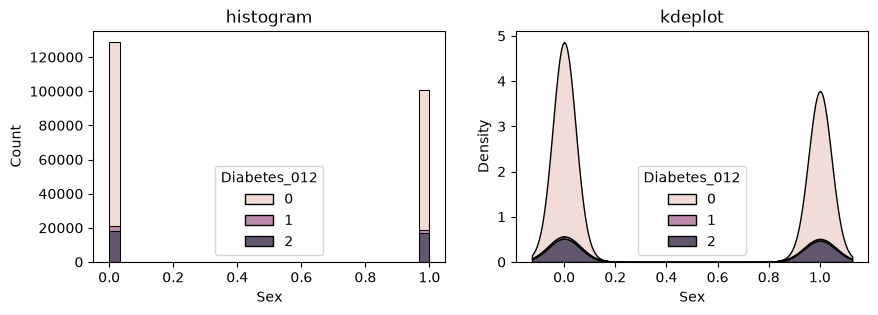

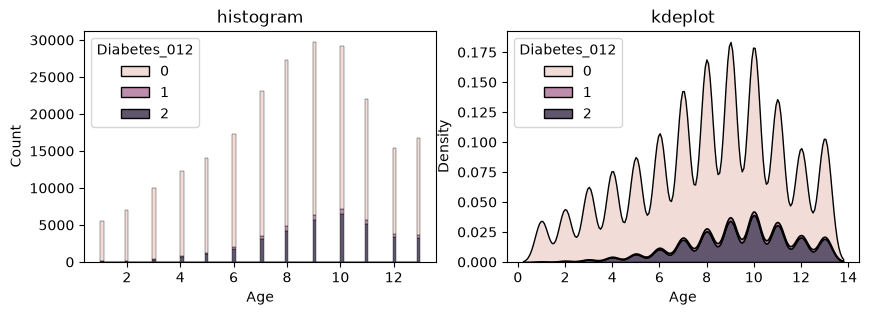

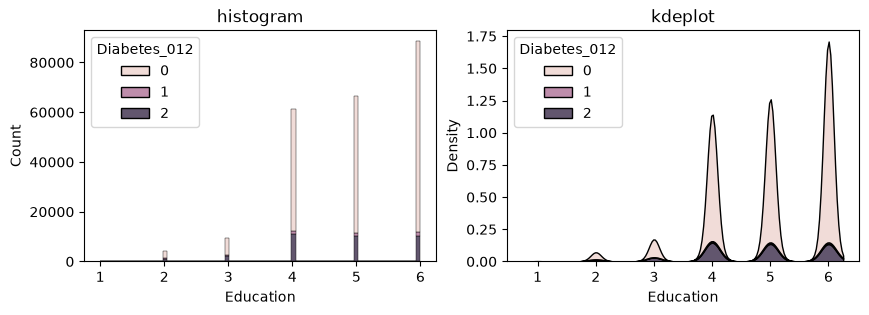

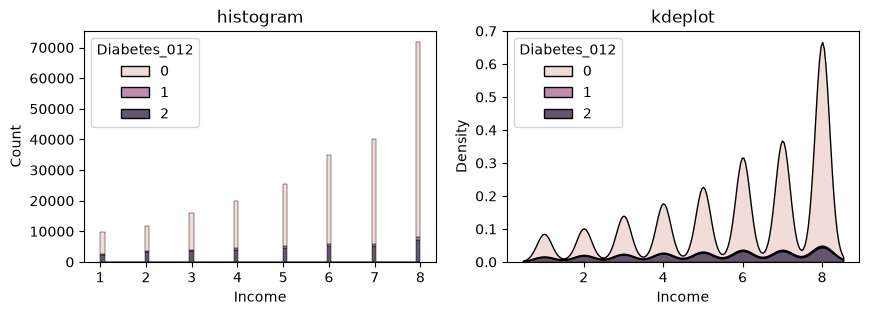

In [18]:

def ploting_hist_kde(data , x ):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(data  = data,x = x , hue= 'Diabetes_012' , multiple = 'stack' , ax = ax1)
    ax1.set_title('histogram')

    sns.kdeplot(data= data , x = x, hue = 'Diabetes_012' , multiple= 'stack' , ax = ax2 )
    ax2.set_title('kdeplot')


for col in diabetes.columns :
    ploting_hist_kde(diabetes ,col)
    




